# 40 · Kriging con SoilGrids 250 m: pH y carbono orgánico (suelos)

**Autora:** Katalina (`@kataleyva`)

| Concepto | Cómo se define |
|---|---|
| **Entradas** | `datos/comunes/altillanura_municipios.gpkg` (cuaderno 01, Michelle) · `datos/comunes/grilla_2km.gpkg` (cuaderno 02, Daniel) · SoilGrids 2.0 por WCS (se descarga si no existe en `datos/suelos/soilgrids/`) |
| **Salidas** (`datos/suelos/soilgrids/`) | `soilgrids_ph_0_30.tif`, `soilgrids_cos_gkg_0_30.tif`, `muestra_puntos_soilgrids.csv`, `descriptivo_por_municipio.csv`, `descriptivo_por_profundidad.csv`, `kriging_ph_0_30*.tif`, `kriging_cos_0_30*.tif` (predicción y varianza, grilla 2 km), `resumen_validacion_soilgrids.csv`, `benchmark_idw_vs_kriging.csv`, `kriging_celda.csv` (predicción por `id_celda`) |
| **Lo usan** | 41_suelos_validacion, 42_suelos_agregacion |
| **Sistema de coordenadas** | EPSG:9377 (MAGNA-SIRGAS Origen Nacional) |
| **Datos pesados** | Los GeoTIFF de `datos/suelos/` van en DVC, no en Git |

**Zona de estudio:** Puerto López, Puerto Gaitán y Mapiripán (Meta); Puerto Carreño, La Primavera, Santa Rosalía y Cumaribo (Vichada).

**Fuente:** SoilGrids 2.0 de ISRIC, servicio WCS `https://maps.isric.org`. 
Propiedades: En agua (`phh2o`) y Carbono orgánico del suelo (`soc`), profundidades 0-5, 5-15 y 15-30 cm (valor medio predicho).

Cada píxel de 250 m es una predicción de un modelo de *machine learning* (bosques aleatorios de cuantiles) entrenado con perfiles de suelo de todo el mundo (en gran parte de WoSIS) y covariables ambientales (clima, relieve, vegetación, geología). En la Altillanura hay muy pocos perfiles de entrenamiento (ver cuaderno 41), así que el mapa refleja sobre todo la relación con las covariables.

**¿Para qué hacer Kriging sobre un raster que ya cubre toda el área?** Como ejercicio controlado: se simula una campaña de muestreo tomando puntos al azar del raster, se interpola con Kriging y se compara el resultado con el raster completo, que hace de "verdad conocida". Esto permite ver qué tanto detalle recupera el Kriging con un número dado de puntos.


## 0. ¿Qué es SoilGrids y cómo se hizo?

**SoilGrids 2.0** es un mapa mundial de propiedades del suelo publicado por ISRIC (2021). En pocas palabras:

* **Cómo se hizo:** un modelo de *machine learning* (**bosques aleatorios de cuantiles**, *quantile random forest*) aprendió de unos **240.000 perfiles de suelo** de todo el mundo (en su mayoría de WoSIS) la relación entre el suelo y unas **400 covariables** que sí cubren todo el planeta: clima, relieve, vegetación vista por satélite, geología, cobertura del suelo. Con esa relación **predice** el suelo en cada píxel, incluso donde nunca se midió nada.
* **Resolución:** píxeles de **250 m** (en su proyección original Homolosine; aquí se descargan reproyectados a ≈ 278 m en EPSG:4326).
* **Profundidades fijas:** 0-5, 5-15, 15-30, 30-60, 60-100 y 100-200 cm. Aquí se usan las tres primeras y se combinan en 0-30 cm.
* **Qué entrega:** para cada píxel, la media, la mediana y los percentiles 5 y 95 (rango de incertidumbre). Aquí se descarga solo la **media**.
* **Unidades escaladas:** pH × 10 y carbono orgánico en dg/kg (se convierten en la sección C).
* **Sin dimensión temporal:** no representa un año concreto; mezcla perfiles de varias décadas, así que no refleja cambios recientes de uso del suelo.
* **Licencia:** CC-BY 4.0 (se puede usar citando a ISRIC).

**Limitaciones en la Altillanura:** hay muy pocos perfiles de entrenamiento en la zona (ver cuaderno 41), así que el modelo se apoya casi solo en las covariables; además, como probablemente se entrenó con los mismos perfiles WoSIS, compararlo con WoSIS resulta optimista.

> Las cifras del método (número de perfiles y de covariables) se citan de memoria: conviene confirmarlas en **Poggio et al. (2021), *SoilGrids 2.0: producing soil information for the globe with quantified spatial uncertainty*, SOIL 7: 217-240** antes de usarlas en el informe.

In [30]:
import sys, subprocess
if 'google.colab' in sys.modules:   # Colab no trae estas librerías
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pykrige', 'gstools', 'rasterio'], check=True)

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests
import shapely
import rasterio
from rasterio import features
from rasterio.transform import from_origin
from rasterio.warp import reproject, Resampling
import gstools as gs
from scipy import stats
from scipy.optimize import curve_fit
from scipy.spatial.distance import pdist
from pykrige.ok import OrdinaryKriging
from pykrige import variogram_models as vm
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100


# Rutas del proyecto: funcionan en Colab y en local (celda estándar de 00_configuracion)
import os, sys, subprocess
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
    os.chdir(RAIZ)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))   # el cuaderno está en notebooks/40_suelos/


def traer(ruta):
    """Baja de DVC un archivo pesado del repo si todavía no está."""
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)


COMUNES = Path(RAIZ) / "datos" / "comunes"
DATOS = Path(RAIZ) / "datos" / "suelos"
(DATOS / "soilgrids").mkdir(parents=True, exist_ok=True)
print("Raíz del repo:", RAIZ)

CRS_M = "EPSG:9377"                 # MAGNA-SIRGAS Origen Nacional (acuerdo del equipo)
MUNICIPIOS = {                      # DIVIPOLA como texto de 5 dígitos
    "50573": ("Puerto López", "Meta"), "50568": ("Puerto Gaitán", "Meta"), "50325": ("Mapiripán", "Meta"),
    "99001": ("Puerto Carreño", "Vichada"), "99524": ("La Primavera", "Vichada"),
    "99624": ("Santa Rosalía", "Vichada"), "99773": ("Cumaribo", "Vichada"),
}
AREA_COMUN_KM2 = 135_649            # área total con los límites comunes (MGN 2025)
CELDA = 2000                       # tamaño de la grilla común (cuaderno 02, Daniel)
SEMILLA = 42


def fuente(texto="Fuente: SoilGrids 2.0 (ISRIC), 0-30 cm; límites DANE MGN 2025."):
    """Pie de figura con la fuente (regla de figuras del equipo)."""
    plt.figtext(0.01, -0.02, texto, fontsize=8, ha="left")


Raíz del repo: c:\Proyectos\Proyecto-ALTILLANURA


## A. Datos de entrada

### A.1 Límites municipales comunes (`datos/comunes/altillanura_municipios.gpkg`, DANE MGN 2025)
Son los mismos límites de todo el proyecto, para que el área y los bordes coincidan con las otras partes.

In [31]:
def cargar_municipios():
    traer("datos/comunes/altillanura_municipios.gpkg")
    g = gpd.read_file(COMUNES / "altillanura_municipios.gpkg")
    g["cod_mun"] = g["mpio_cdpmp"].astype(str).str.zfill(5)        # DIVIPOLA (cuaderno 01)
    g = g[g["cod_mun"].isin(MUNICIPIOS)].copy()
    g["municipio"] = g["cod_mun"].map(lambda c: MUNICIPIOS[c][0])
    g["departamento"] = g["cod_mun"].map(lambda c: MUNICIPIOS[c][1])
    # SoilGrids se descarga en EPSG:4326, así que los límites se usan en 4326 para rasterizar
    return g[["cod_mun", "municipio", "departamento", "geometry"]].to_crs("EPSG:4326").reset_index(drop=True)


mun = cargar_municipios()
mun_m = mun.to_crs(CRS_M)
mun["area_km2"] = (mun_m.area / 1e6).round(0).values
display(mun.drop(columns="geometry"))
total = mun["area_km2"].sum()
print(f"Área total: {total:,.0f} km² (acuerdo del equipo: {AREA_COMUN_KM2:,} km²)")
assert len(mun) == 7, "Faltan municipios en el archivo común"
assert abs(total - AREA_COMUN_KM2) / AREA_COMUN_KM2 < 0.005, "El área no coincide con los límites comunes"

# Caja para pedir SoilGrids: sale de los límites comunes + margen de 0.05° (≈ 5,5 km), redondeada a 0.01°
b = mun.total_bounds
BBOX = (float(np.floor((b[0] - 0.05) * 100) / 100), float(np.floor((b[1] - 0.05) * 100) / 100),
        float(np.ceil((b[2] + 0.05) * 100) / 100), float(np.ceil((b[3] + 0.05) * 100) / 100))
print("Caja para SoilGrids (lon_min, lat_min, lon_max, lat_max):", BBOX)


,cod_mun,municipio,departamento,area_km2
0,50325,Mapiripán,Meta,11917.0
1,50568,Puerto Gaitán,Meta,17201.0
2,50573,Puerto López,Meta,6898.0
3,99001,Puerto Carreño,Vichada,12142.0
4,99524,La Primavera,Vichada,18492.0
5,99624,Santa Rosalía,Vichada,3679.0
6,99773,Cumaribo,Vichada,65319.0


Área total: 135,648 km² (acuerdo del equipo: 135,649 km²)
Caja para SoilGrids (lon_min, lat_min, lon_max, lat_max): (-73.32, 2.67, -67.35, 6.38)


### A.2 Rasters de SoilGrids por WCS
Cada propiedad tiene su propio servicio WCS (`map=/map/phh2o.map`, `map=/map/soc.map`) y cada capa se llama `<propiedad>_<profundidad>_mean`. Se pide el recorte de la caja directamente en coordenadas geográficas (EPSG:4326) con resolución de 0.0025° (≈ 278 m, cercana a los 250 m nativos; el servidor reproyecta desde la proyección Homolosine original). Cada descarga tarda alrededor de un minuto; si el archivo ya existe en `datos/soilgrids/` no se descarga de nuevo.

In [32]:
PROPIEDADES = ["phh2o", "soc"]
PROFUNDIDADES = ["0-5cm", "5-15cm", "15-30cm"]
RES = 0.0025


def descargar_wcs(prop, prof):
    destino = DATOS / "soilgrids" / f"{prop}_{prof}_mean.tif"
    if destino.exists():
        print(f"{destino.name}: ya existe")
        return destino
    params = [
        ("map", f"/map/{prop}.map"), ("SERVICE", "WCS"), ("VERSION", "2.0.1"), ("REQUEST", "GetCoverage"),
        ("COVERAGEID", f"{prop}_{prof}_mean"), ("FORMAT", "image/tiff"),
        ("SUBSET", f"long({BBOX[0]},{BBOX[2]})"), ("SUBSET", f"lat({BBOX[1]},{BBOX[3]})"),
        ("SUBSETTINGCRS", "http://www.opengis.net/def/crs/EPSG/0/4326"),
        ("OUTPUTCRS", "http://www.opengis.net/def/crs/EPSG/0/4326"),
        ("RESOLUTION", f"long({RES})"), ("RESOLUTION", f"lat({RES})"),
    ]
    for intento in range(3):
        try:
            r = requests.get("https://maps.isric.org/mapserv", params=params, timeout=900)
            r.raise_for_status()
            if not r.content[:4] in (b"II*\x00", b"MM\x00*"):
                raise ValueError(r.text[:300])
            destino.write_bytes(r.content)
            print(f"{destino.name}: {len(r.content) / 1e6:.1f} MB")
            return destino
        except Exception as e:
            print(f"  intento {intento + 1} falló: {e}")
    raise RuntimeError(f"No se pudo descargar {prop} {prof}")


archivos = {(p, d): descargar_wcs(p, d) for p in PROPIEDADES for d in PROFUNDIDADES}

phh2o_0-5cm_mean.tif: ya existe
phh2o_5-15cm_mean.tif: ya existe
phh2o_15-30cm_mean.tif: ya existe
soc_0-5cm_mean.tif: ya existe
soc_5-15cm_mean.tif: ya existe
soc_15-30cm_mean.tif: ya existe


## B. Análisis exploratorio (EDA)

### B.1 Metadatos de los rasters
Se revisan dimensiones, resolución, tipo de dato, sistema de referencia y el valor que marca "sin dato". SoilGrids guarda los valores como enteros escalados (para ahorrar espacio): **pH × 10** y **COS en dg/kg** (decigramos por kilogramo).

In [33]:
crudos, filas = {}, []
for (p, d), f in archivos.items():
    with rasterio.open(f) as src:
        a = src.read(1)
        transform, crs_r, shape = src.transform, src.crs, a.shape
        filas.append({"archivo": f.name, "filas x columnas": f"{a.shape[0]} x {a.shape[1]}",
                      "resolución (°)": round(src.res[0], 5), "tipo": a.dtype.name, "crs": str(src.crs),
                      "nodata declarado": src.nodata, "mín": int(a.min()), "máx": int(a.max()),
                      "% píxeles = 0": round((a == 0).mean() * 100, 2)})
        crudos[(p, d)] = a
display(pd.DataFrame(filas))

,archivo,filas x columnas,resolución (°),tipo,crs,nodata declarado,mín,máx,% píxeles = 0
0,phh2o_0-5cm_mean.tif,1484 x 2388,0.0025,int16,EPSG:4326,None,0,67,1.39
1,phh2o_5-15cm_mean.tif,1484 x 2388,0.0025,int16,EPSG:4326,None,0,67,1.39
2,phh2o_15-30cm_mean.tif,1484 x 2388,0.0025,int16,EPSG:4326,None,0,67,1.39
3,soc_0-5cm_mean.tif,1484 x 2388,0.0025,int16,EPSG:4326,None,0,1803,1.40
4,soc_5-15cm_mean.tif,1484 x 2388,0.0025,int16,EPSG:4326,None,0,1408,1.40
5,soc_15-30cm_mean.tif,1484 x 2388,0.0025,int16,EPSG:4326,None,0,1189,1.40


El archivo no declara un valor *nodata*, pero hay píxeles con valor **0**. Un pH de 0 o un COS de exactamente 0 en el suelo superficial no son físicamente posibles: corresponden a áreas sin predicción (agua, zonas urbanas o bordes). Se tratan como nulos.

### B.2 Nulos dentro de los municipios
Se construye una máscara de los 7 municipios sobre la grilla del raster para contar los nulos solo dentro del área de estudio.

In [34]:
en_mun = features.geometry_mask(mun.geometry, out_shape=shape, transform=transform, invert=True)
id_mun = features.rasterize(((g, i + 1) for i, g in enumerate(mun.geometry)), out_shape=shape,
                            transform=transform, fill=0, dtype="int16")
print(f"Píxeles dentro de los municipios: {en_mun.sum():,}")
nul = pd.DataFrame({f"{p} {d}": {"nulos (valor 0)": int(((a == 0) & en_mun).sum()),
                                 "% nulos": round(((a == 0) & en_mun).sum() / en_mun.sum() * 100, 2)}
                    for (p, d), a in crudos.items()}).T
display(nul)

Píxeles dentro de los municipios: 1,765,825


,nulos (valor 0),% nulos
phh2o 0-5cm,21588.0,1.22
phh2o 5-15cm,21588.0,1.22
phh2o 15-30cm,21588.0,1.22
soc 0-5cm,21612.0,1.22
soc 5-15cm,21612.0,1.22
soc 15-30cm,21612.0,1.22


### B.3 Limpieza y estandarización del raster
(La limpieza del raster va antes de los mapas y de la muestra, porque los puntos se toman del raster ya limpio.)

**Nodata y unidades**
* 0 → nulo (`NaN`).
* pH: valor / 10.
* COS: dg/kg / 10 → **g/kg** (1 % = 10 g/kg), las mismas unidades que WoSIS.

**Profundidad estandarizada 0-30 cm**
Promedio ponderado por el espesor de cada intervalo: 0-5 cm (5 cm), 5-15 cm (10 cm) y 15-30 cm (15 cm):

$$v_{0-30} = \frac{5\,v_{0-5} + 10\,v_{5-15} + 15\,v_{15-30}}{30}$$

Si falta cualquiera de las tres profundidades en un píxel, el valor 0-30 queda nulo (no se imputa).

In [35]:
ESCALA = {"phh2o": 10.0, "soc": 10.0}
PESOS = {"0-5cm": 5, "5-15cm": 10, "15-30cm": 15}
r030 = {}
for p in PROPIEDADES:
    acum = np.zeros(shape)
    for d, w in PESOS.items():
        a = crudos[(p, d)].astype("float64")
        a[a == 0] = np.nan
        acum += w * a / ESCALA[p]
    r030[p] = acum / sum(PESOS.values())
r030["ph"] = r030.pop("phh2o")
r030["cos_gkg"] = r030.pop("soc")

for k, a in r030.items():
    with rasterio.open(DATOS / "soilgrids" / f"soilgrids_{k}_0_30.tif", "w", driver="GTiff", height=shape[0],
                       width=shape[1], count=1, dtype="float32", crs=crs_r, transform=transform, nodata=np.nan) as dst:
        dst.write(a.astype("float32"), 1)

desc = pd.DataFrame({k: pd.Series(a[en_mun]).describe() for k, a in r030.items()}).T
desc["nulos"] = [int(np.isnan(a[en_mun]).sum()) for a in r030.values()]
desc["asimetría"] = [round(stats.skew(a[en_mun & np.isfinite(a)]), 2) for a in r030.values()]
print("Raster 0-30 cm dentro de los municipios (todas las celdas de ~278 m):")
display(desc.round(2))

Raster 0-30 cm dentro de los municipios (todas las celdas de ~278 m):


,count,mean,std,min,25%,50%,75%,max,nulos,asimetría
ph,1744237.0,5.02,0.22,4.25,4.80,5.10,5.20,5.70,21588,-0.58
cos_gkg,1744213.0,19.59,4.61,10.55,16.77,18.58,20.97,75.27,21612,2.57


### B.4 Mapas e histogramas del raster 0-30 cm

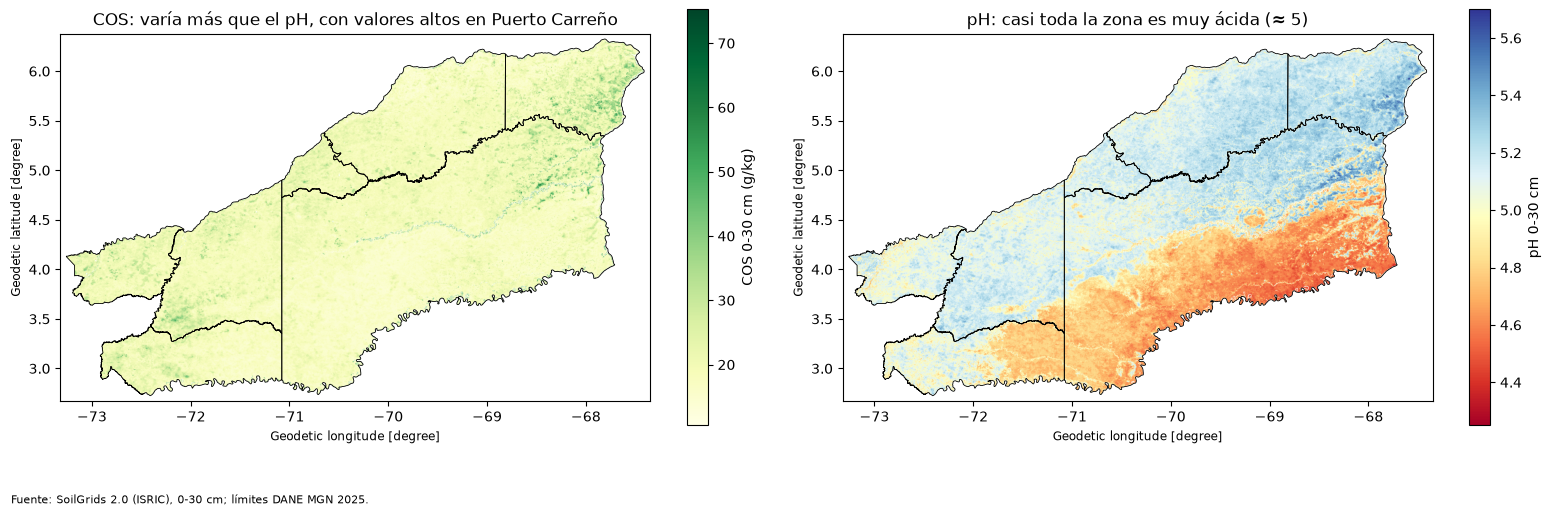

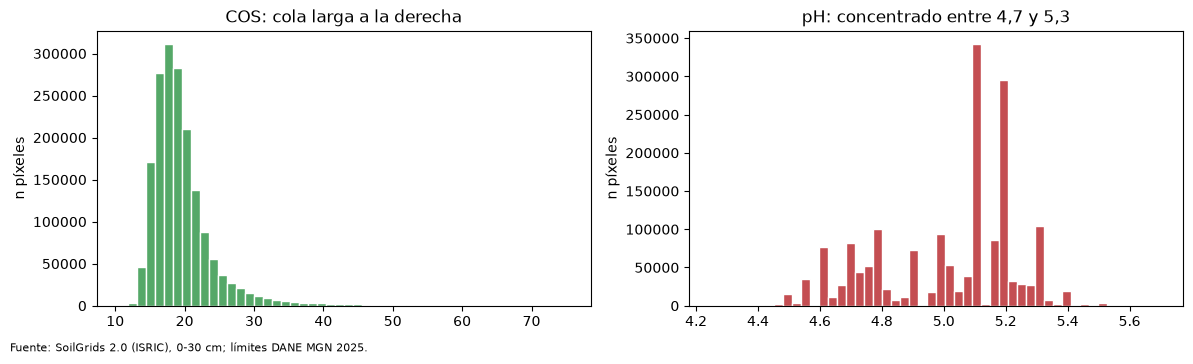

In [36]:
ext_r = [BBOX[0], BBOX[2], BBOX[1], BBOX[3]]
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
for a_, (k, cmap, et) in zip(ax, [("cos_gkg", "YlGn", "COS 0-30 cm (g/kg)"), ("ph", "RdYlBu", "pH 0-30 cm")]):
    im = a_.imshow(np.where(en_mun, r030[k], np.nan), extent=ext_r, cmap=cmap)
    plt.colorbar(im, ax=a_, shrink=0.8, label=et)
    mun.boundary.plot(ax=a_, color="k", lw=0.6)
    a_.set_title({"COS 0-30 cm (g/kg)": "COS: varía más que el pH, con valores altos en Puerto Carreño", "pH 0-30 cm": "pH: casi toda la zona es muy ácida (≈ 5)"}.get(et, et))
plt.tight_layout()
fuente()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a_, (k, et, c) in zip(ax, [("cos_gkg", "COS 0-30 cm (g/kg)", "#55A868"), ("ph", "pH 0-30 cm", "#C44E52")]):
    v = r030[k][en_mun]
    a_.hist(v[np.isfinite(v)], bins=50, color=c, edgecolor="white")
    a_.set_title({"COS 0-30 cm (g/kg)": "COS: cola larga a la derecha", "pH 0-30 cm": "pH: concentrado entre 4,7 y 5,3"}.get(et, et)); a_.set_ylabel("n píxeles")
plt.tight_layout()
fuente()
plt.show()

### B.5 Muestra de puntos (simulación de un muestreo)
Se toman al azar (semilla fija = 42, para que sea reproducible):
* **300 puntos de calibración**: los que se usan para el Kriging (≈ 1 punto cada 450 km², separación típica de ~20 km).
* **200 puntos de validación independiente**: no se usan en el Kriging; sirven para comprobar la predicción.

Solo se muestrean píxeles **dentro de los municipios y con valor válido** en ambas propiedades. Cada punto se ubica en el centro del píxel.

In [37]:
N_CAL, N_VAL = 300, 200
validos = en_mun & np.isfinite(r030["cos_gkg"]) & np.isfinite(r030["ph"])
filas_v, cols_v = np.nonzero(validos)
rng = np.random.default_rng(SEMILLA)
idx = rng.choice(len(filas_v), N_CAL + N_VAL, replace=False)
fr, cr = filas_v[idx], cols_v[idx]
lon, lat = rasterio.transform.xy(transform, fr, cr)
muestra = gpd.GeoDataFrame({
    "lon": lon, "lat": lat,
    "cos_gkg": r030["cos_gkg"][fr, cr], "ph": r030["ph"][fr, cr],
    "conjunto": ["calibración"] * N_CAL + ["validación"] * N_VAL,
}, geometry=gpd.points_from_xy(lon, lat), crs="EPSG:4326")
muestra["municipio"] = mun["municipio"].values[id_mun[fr, cr] - 1]
muestra["departamento"] = mun["departamento"].values[id_mun[fr, cr] - 1]
muestra.drop(columns="geometry").to_csv(DATOS / "soilgrids" / "muestra_puntos_soilgrids.csv", index=False)
print("Dimensiones:", muestra.shape)
display(pd.DataFrame({"tipo": muestra.dtypes.astype(str), "valores_unicos": muestra.nunique()}))
display(muestra.head())

Dimensiones: (500, 8)


,tipo,valores_unicos
lon,float64,443
lat,float64,406
cos_gkg,float64,360
ph,float64,44
conjunto,str,2
geometry,geometry,500
municipio,str,7
departamento,str,2


,lon,lat,cos_gkg,ph,conjunto,geometry,municipio,departamento
0,-70.09125,5.53375,18.183333,5.100000,calibración,POINT (-70.09125 5.53375),La Primavera,Vichada
1,-69.70125,3.65375,16.716667,4.666667,calibración,POINT (-69.70125 3.65375),Cumaribo,Vichada
2,-68.56875,4.14625,19.033333,4.600000,calibración,POINT (-68.56875 4.14625),Cumaribo,Vichada
3,-70.37375,4.06875,14.583333,4.900000,calibración,POINT (-70.37375 4.06875),Cumaribo,Vichada
4,-69.41125,4.96375,18.300000,5.300000,calibración,POINT (-69.41125 4.96375),Cumaribo,Vichada


### B.6 Nulos y duplicados de la muestra

In [38]:
display(pd.DataFrame({"nulos": muestra.isna().sum(), "% nulos": (muestra.isna().mean() * 100).round(1)}).T)
print("Filas duplicadas:", muestra.drop(columns="geometry").duplicated().sum())
print("Coordenadas repetidas:", muestra[["lon", "lat"]].round(6).duplicated().sum())

,lon,lat,cos_gkg,ph,conjunto,geometry,municipio,departamento
nulos,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
% nulos,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Filas duplicadas: 0
Coordenadas repetidas: 0


### B.7 Estadísticos descriptivos, distribución y atípicos

conjunto       calibración  validación
cos_gkg count       300.00      200.00
        mean         19.13       19.65
        std           4.21        4.58
        min          13.40       12.62
        25%          16.45       16.94
        50%          18.22       18.68
        75%          20.60       20.60
        max          43.92       48.70
ph      count       300.00      200.00
        mean          4.99        5.05
        std           0.23        0.22
        min           4.50        4.50
        25%           4.80        4.92
        50%           5.07        5.10
        75%           5.20        5.20
        max           5.48        5.50

Atípicos (regla IQR) en la muestra de calibración:


,n,lim_inf,lim_sup,n_atipicos
cos_gkg,300.0,10.21,26.84,16.0
ph,300.0,4.20,5.80,0.0


Asimetría: {'cos_gkg': 2.17, 'ph': -0.36}


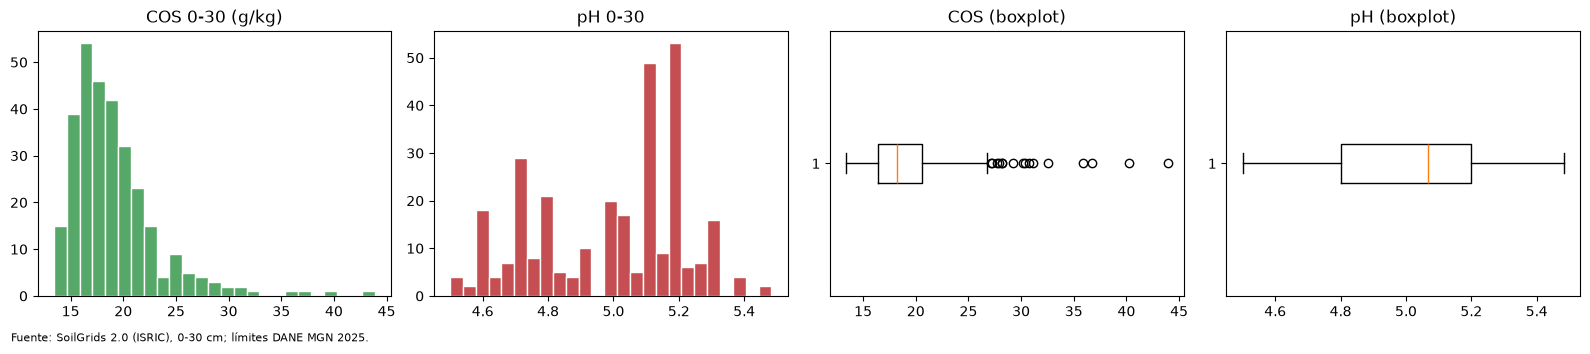

In [39]:
display(muestra.groupby("conjunto")[["cos_gkg", "ph"]].describe().T.round(2))


def atipicos_iqr(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"n": len(s), "lim_inf": li, "lim_sup": ls, "n_atipicos": int(((s < li) | (s > ls)).sum())})


cal = muestra[muestra["conjunto"] == "calibración"].copy()
print("Atípicos (regla IQR) en la muestra de calibración:")
display(cal[["cos_gkg", "ph"]].apply(atipicos_iqr).T.round(2))
print("Asimetría:", cal[["cos_gkg", "ph"]].skew().round(2).to_dict())

fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
ax[0].hist(cal["cos_gkg"], bins=25, color="#55A868", edgecolor="white"); ax[0].set_title("COS 0-30 (g/kg)")
ax[1].hist(cal["ph"], bins=25, color="#C44E52", edgecolor="white"); ax[1].set_title("pH 0-30")
ax[2].boxplot(cal["cos_gkg"], vert=False); ax[2].set_title("COS (boxplot)")
ax[3].boxplot(cal["ph"], vert=False); ax[3].set_title("pH (boxplot)")
plt.tight_layout()
fuente()
plt.show()

### B.8 Puntos por municipio y departamento
Con muestreo aleatorio simple, el % de puntos por municipio debe parecerse al % de área.

In [40]:
pm = muestra.groupby(["departamento", "municipio"]).size().rename("puntos").reset_index()
pm["% puntos"] = (pm["puntos"] / pm["puntos"].sum() * 100).round(1)
pm["% área"] = pm["municipio"].map(mun.set_index("municipio")["area_km2"] / mun["area_km2"].sum() * 100).round(1)
display(pm)
dd = muestra["departamento"].value_counts().rename("puntos").to_frame()
dd["%"] = (dd["puntos"] / dd["puntos"].sum() * 100).round(1)
display(dd)

,departamento,municipio,puntos,% puntos,% área
0,Meta,Mapiripán,45,9.0,8.8
1,Meta,Puerto Gaitán,62,12.4,12.7
2,Meta,Puerto López,23,4.6,5.1
3,Vichada,Cumaribo,245,49.0,48.2
4,Vichada,La Primavera,71,14.2,13.6
5,Vichada,Puerto Carreño,43,8.6,9.0
6,Vichada,Santa Rosalía,11,2.2,2.7


,puntos,%
departamento,,
Vichada,370,74.0
Meta,130,26.0


### B.9 Mapa de puntos

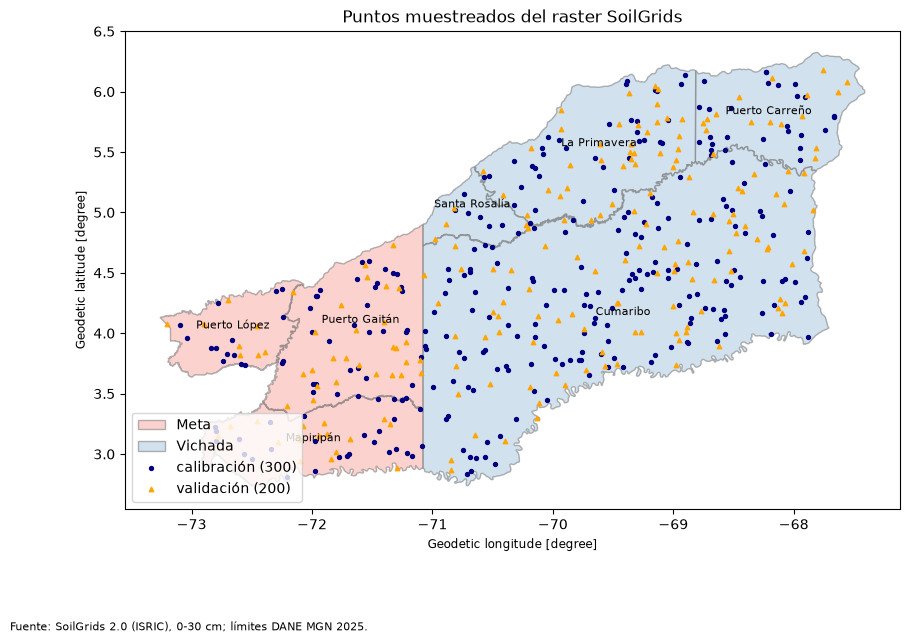

In [41]:
fig, ax = plt.subplots(figsize=(10, 7))
mun.plot(ax=ax, column="departamento", cmap="Pastel1", edgecolor="grey", alpha=0.6)
for _, r in mun.iterrows():
    p = r.geometry.representative_point()
    ax.annotate(r["municipio"], (p.x, p.y), fontsize=8, ha="center")
muestra[muestra["conjunto"] == "calibración"].plot(ax=ax, color="navy", markersize=8, label=f"calibración ({N_CAL})")
muestra[muestra["conjunto"] == "validación"].plot(ax=ax, color="orange", marker="^", markersize=10,
                                                  label=f"validación ({N_VAL})")
ax.legend(loc="lower left")
ax.set_title("Puntos muestreados del raster SoilGrids")
fuente()
plt.show()

## C. Limpieza de la muestra
* **Nulos:** no hay, porque solo se muestrearon píxeles válidos. Los píxeles nulos del raster (agua, zonas sin predicción) se **excluyen** en lugar de imputarse: inventar un valor de suelo donde hay agua no tiene sentido, y el Kriging ya se encarga de estimar los sitios sin dato.
* **Duplicados:** el muestreo es sin reemplazo, así que no hay coordenadas repetidas; si las hubiera se promediarían, igual que en el notebook de WoSIS.
* **Atípicos:** se conservan (son valores del propio modelo, no errores de digitación).
* **Transformación:** se compara la asimetría del COS antes y después del logaritmo.

Puntos de calibración tras agrupar por coordenada: 300
Asimetría COS: 2.16 | log(COS): 1.21 | pH: -0.36


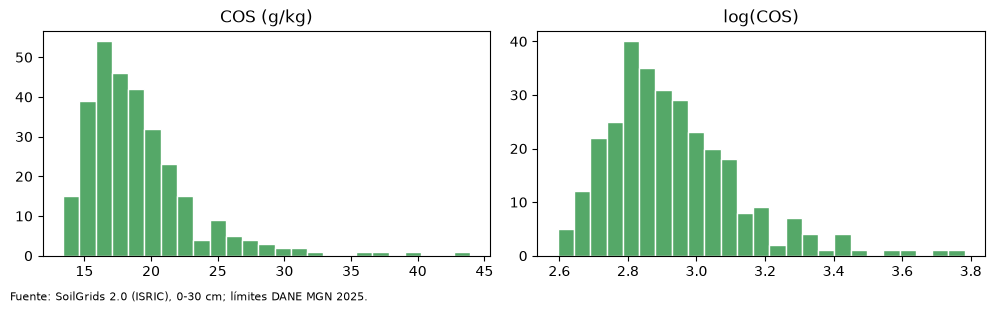

In [42]:
cal = cal.groupby(["lon", "lat"], as_index=False).agg({"cos_gkg": "mean", "ph": "mean", "municipio": "first",
                                                       "departamento": "first"})
cal = gpd.GeoDataFrame(cal, geometry=gpd.points_from_xy(cal["lon"], cal["lat"]), crs="EPSG:4326")
cal["log_cos"] = np.log(cal["cos_gkg"])
print(f"Puntos de calibración tras agrupar por coordenada: {len(cal)}")
print("Asimetría COS:", round(stats.skew(cal["cos_gkg"]), 2), "| log(COS):", round(stats.skew(cal["log_cos"]), 2),
      "| pH:", round(stats.skew(cal["ph"]), 2))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(cal["cos_gkg"], bins=25, color="#55A868", edgecolor="white"); ax[0].set_title("COS (g/kg)")
ax[1].hist(cal["log_cos"], bins=25, color="#55A868", edgecolor="white"); ax[1].set_title("log(COS)")
plt.tight_layout()
fuente()
plt.show()

**Decisión:** el COS de SoilGrids tiene una cola larga a la derecha (asimetría ≈ 2.2; unos pocos píxeles con mucho carbono). El logaritmo la reduce a la mitad (≈ 1.2), así que el COS se interpola en escala logarítmica y se regresa a g/kg con `exp()`, igual que en el notebook de WoSIS. El pH es casi simétrico y se interpola sin transformar.

### C.1 Proyección a metros
Se proyecta a **EPSG:9377** (MAGNA-SIRGAS Origen Nacional) para que las distancias estén en metros.

In [43]:
cal_m = cal.to_crs(CRS_M)
val_m = muestra[muestra["conjunto"] == "validación"].to_crs(CRS_M)
print(len(cal_m), "puntos de calibración |", len(val_m), "puntos de validación")

300 puntos de calibración | 200 puntos de validación


## D. Análisis descriptivo: ¿qué dice SoilGrids de la Altillanura?

Antes del ejercicio de Kriging, se describe el raster SoilGrids **completo** (todos los píxeles de ≈ 278 m dentro de los 7 municipios, ≈ 1,7 millones), no la muestra de puntos.

### D.1 pH y COS 0-30 cm por municipio
Para cada municipio: **media**, **mediana**, **p10** y **p90** (el 80 % central de los píxeles está entre p10 y p90).

In [44]:
validos_d = en_mun & np.isfinite(r030["ph"]) & np.isfinite(r030["cos_gkg"])
filas = []
for i, m in enumerate(mun["municipio"]):
    s = validos_d & (id_mun == i + 1)
    fila = {"municipio": m, "departamento": mun["departamento"].iloc[i], "píxeles": int(s.sum())}
    for k in ["ph", "cos_gkg"]:
        v = r030[k][s]
        fila.update({f"{k} media": v.mean(), f"{k} mediana": np.median(v),
                     f"{k} p10": np.percentile(v, 10), f"{k} p90": np.percentile(v, 90)})
    filas.append(fila)
v_ph, v_cos = r030["ph"][validos_d], r030["cos_gkg"][validos_d]
filas.append({"municipio": "TOTAL 7 municipios", "departamento": "", "píxeles": int(validos_d.sum()),
              "ph media": v_ph.mean(), "ph mediana": np.median(v_ph),
              "ph p10": np.percentile(v_ph, 10), "ph p90": np.percentile(v_ph, 90),
              "cos_gkg media": v_cos.mean(), "cos_gkg mediana": np.median(v_cos),
              "cos_gkg p10": np.percentile(v_cos, 10), "cos_gkg p90": np.percentile(v_cos, 90)})
por_mun = pd.DataFrame(filas).set_index("municipio")
por_mun.to_csv(DATOS / "soilgrids" / "descriptivo_por_municipio.csv")
display(por_mun.round(2))
print(f"Píxeles con pH > 5.5: {(v_ph > 5.5).mean() * 100:.2f} % del área")

,departamento,píxeles,ph media,ph mediana,ph p10,ph p90,cos_gkg media,cos_gkg mediana,cos_gkg p10,cos_gkg p90
municipio,,,,,,,,,,
Mapiripán,Meta,154312,4.94,4.97,4.72,5.12,19.27,18.27,15.47,24.20
Puerto Gaitán,Meta,223413,5.11,5.10,5.00,5.20,20.39,19.50,16.60,25.28
Puerto López,Meta,89026,5.07,5.10,4.97,5.20,21.26,20.33,17.25,26.53
Puerto Carreño,Vichada,153662,5.22,5.20,5.10,5.32,22.26,20.23,15.98,31.62
La Primavera,Vichada,238268,5.16,5.20,5.07,5.27,18.93,18.47,15.50,22.68
Santa Rosalía,Vichada,47440,5.12,5.12,5.02,5.20,21.13,20.60,17.58,25.18
Cumaribo,Vichada,838092,4.91,4.90,4.60,5.25,18.87,17.90,15.12,22.72
TOTAL 7 municipios,,1744213,5.02,5.10,4.70,5.25,19.59,18.58,15.45,24.45


Píxeles con pH > 5.5: 0.07 % del área


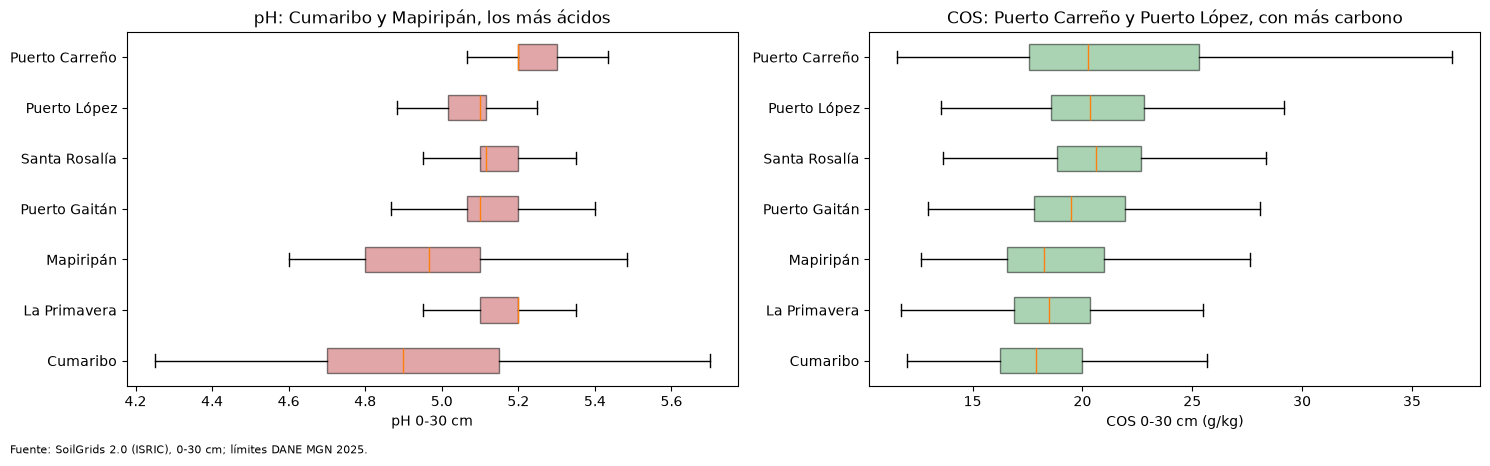

In [45]:
orden = por_mun.drop(index="TOTAL 7 municipios").sort_values("cos_gkg media").index
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a_, (k, et, c) in zip(ax, [("ph", "pH 0-30 cm", "#C44E52"), ("cos_gkg", "COS 0-30 cm (g/kg)", "#55A868")]):
    datos_box = [r030[k][validos_d & (id_mun == mun.index[mun["municipio"] == m][0] + 1)] for m in orden]
    a_.boxplot(datos_box, tick_labels=list(orden), showfliers=False, vert=False,
               patch_artist=True, boxprops={"facecolor": c, "alpha": 0.5})
    a_.set_title({"pH 0-30 cm": "pH: Cumaribo y Mapiripán, los más ácidos", "COS 0-30 cm (g/kg)": "COS: Puerto Carreño y Puerto López, con más carbono"}.get(et, et)); a_.set_xlabel(et)
plt.tight_layout()
fuente()
plt.show()

### D.2 ¿Cómo cambian con la profundidad?
Se usan los rasters originales de cada intervalo (0-5, 5-15 y 15-30 cm), ya convertidos a unidades reales.

media  mediana   p10   p90
propiedad  profundidad                            
pH         0-5cm         5.03      5.1   4.7   5.3
           5-15cm        5.00      5.1   4.7   5.2
           15-30cm       5.02      5.1   4.7   5.3
COS (g/kg) 0-5cm        31.85     30.5  25.2  38.5
           5-15cm       21.30     20.3  15.7  27.5
           15-30cm      14.36     13.5  10.0  19.4

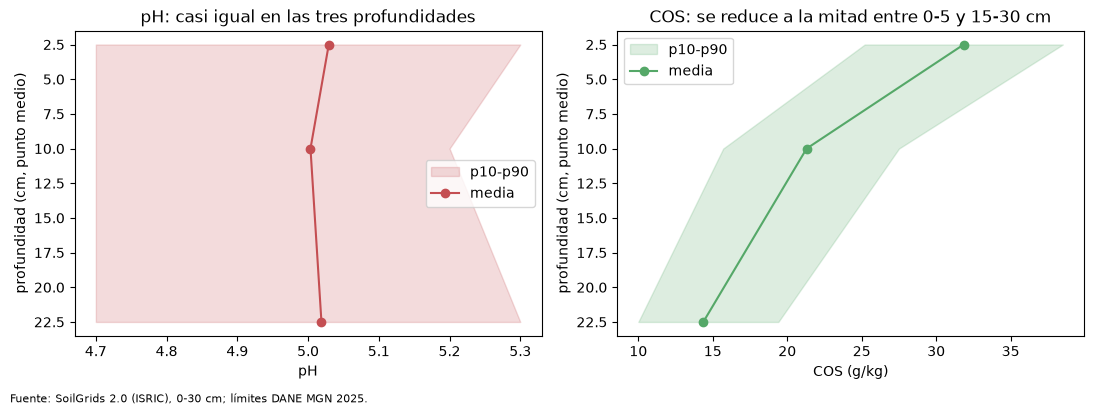

In [46]:
filas = []
for p, k, et in [("phh2o", "ph", "pH"), ("soc", "cos_gkg", "COS (g/kg)")]:
    for d in PROFUNDIDADES:
        a = crudos[(p, d)].astype("float64")
        a[a == 0] = np.nan
        v = a[en_mun] / ESCALA[p]
        v = v[np.isfinite(v)]
        filas.append({"propiedad": et, "profundidad": d, "media": v.mean(), "mediana": np.median(v),
                      "p10": np.percentile(v, 10), "p90": np.percentile(v, 90)})
por_prof = pd.DataFrame(filas)
por_prof.to_csv(DATOS / "soilgrids" / "descriptivo_por_profundidad.csv", index=False)
display(por_prof.set_index(["propiedad", "profundidad"]).round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
prof_cm = [2.5, 10, 22.5]
for a_, (et, c) in zip(ax, [("pH", "#C44E52"), ("COS (g/kg)", "#55A868")]):
    t = por_prof[por_prof["propiedad"] == et]
    a_.fill_betweenx(prof_cm, t["p10"], t["p90"], color=c, alpha=0.2, label="p10-p90")
    a_.plot(t["media"], prof_cm, "o-", color=c, label="media")
    a_.invert_yaxis(); a_.set_ylabel("profundidad (cm, punto medio)"); a_.set_xlabel(et)
    a_.set_title({"pH": "pH: casi igual en las tres profundidades", "COS (g/kg)": "COS: se reduce a la mitad entre 0-5 y 15-30 cm"}.get(et, et)); a_.legend()
plt.tight_layout()
fuente()
plt.show()

### D.3 Por paisaje
Se movió al cuaderno 41, porque usa el mapa del IGAC (antes notebook 05).

### D.4 ¿Van juntos el pH y el carbono?
Correlación entre pH y COS 0-30 cm en todos los píxeles: **Pearson** mide relación lineal; **Spearman** mide si suben o bajan juntos aunque no sea en línea recta. Valores cercanos a 0 = sin relación; cercanos a 1 = relación fuerte.

Correlación pH-COS: Pearson = 0.35 | Spearman = 0.45 (Spearman sobre 50.000 píxeles al azar)


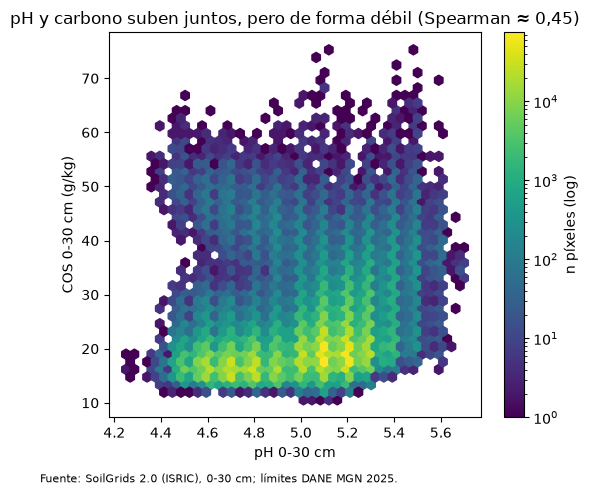

In [47]:
r_p = stats.pearsonr(v_ph, v_cos)[0]
sub = np.random.default_rng(SEMILLA).choice(len(v_ph), 50000, replace=False)
r_s = stats.spearmanr(v_ph[sub], v_cos[sub])[0]
print(f"Correlación pH-COS: Pearson = {r_p:.2f} | Spearman = {r_s:.2f} (Spearman sobre 50.000 píxeles al azar)")
fig, ax = plt.subplots(figsize=(6, 5))
h = ax.hexbin(v_ph, v_cos, gridsize=40, bins="log", cmap="viridis", mincnt=1)
plt.colorbar(h, ax=ax, label="n píxeles (log)")
ax.set_xlabel("pH 0-30 cm"); ax.set_ylabel("COS 0-30 cm (g/kg)")
ax.set_title("pH y carbono suben juntos, pero de forma débil (Spearman ≈ 0,45)")
fuente()
plt.show()

### D.5 Mapas por municipio
Mapas de la media de pH y COS 0-30 cm de cada municipio (los mapas píxel a píxel están en la sección B.3).

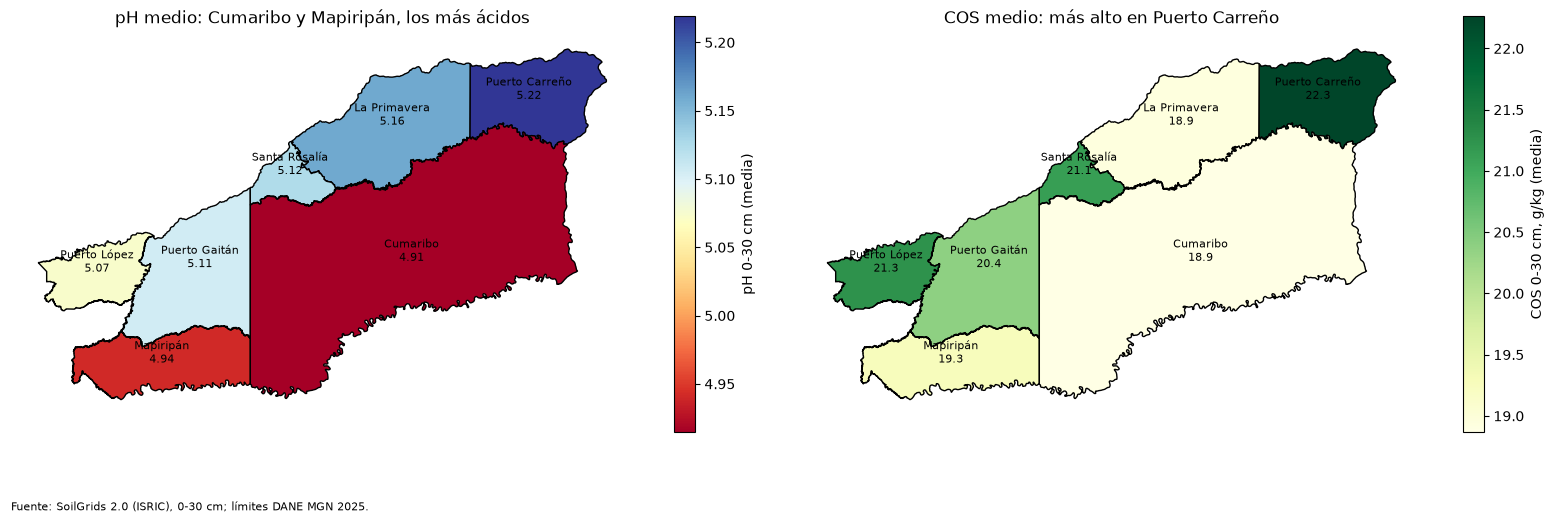

In [48]:
mun_d = mun.merge(por_mun[["ph media", "cos_gkg media"]], left_on="municipio", right_index=True)
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
for a_, (k, cmap, et) in zip(ax, [("ph media", "RdYlBu", "pH 0-30 cm (media)"),
                                  ("cos_gkg media", "YlGn", "COS 0-30 cm, g/kg (media)")]):
    mun_d.plot(ax=a_, column=k, cmap=cmap, edgecolor="k", legend=True, legend_kwds={"label": et, "shrink": 0.8})
    for _, r in mun_d.iterrows():
        p = r.geometry.representative_point()
        a_.annotate(f"{r['municipio']}\n{r[k]:.2f}" if k == "ph media" else f"{r['municipio']}\n{r[k]:.1f}",
                    (p.x, p.y), fontsize=8, ha="center")
    a_.set_title({"pH 0-30 cm (media)": "pH medio: Cumaribo y Mapiripán, los más ácidos", "COS 0-30 cm, g/kg (media)": "COS medio: más alto en Puerto Carreño"}.get(et, et)); a_.set_axis_off()
plt.tight_layout()
fuente()
plt.show()

**Lectura del análisis descriptivo**
* Según SoilGrids, la Altillanura es **muy homogénea en pH**: suelos muy ácidos (≈ 5) en todos los municipios, con diferencias de apenas unas décimas; casi ningún píxel pasa de 5.5. Cumaribo y Mapiripán son los más ácidos.
* El **carbono varía más**: se concentra en la superficie (en 0-5 cm es aproximadamente el doble que en 15-30 cm) y es algo más alto en Puerto Carreño y Puerto López.
* pH y COS tienen una relación **positiva pero débil**.

## E. Kriging ordinario

El Kriging estima cada sitio sin dato como un promedio ponderado de los puntos vecinos; los pesos salen del **semivariograma** (pepita = variación a muy corta distancia, meseta = variación total, rango = distancia a partir de la cual los puntos dejan de parecerse). Se ajustan y comparan los modelos esférico, exponencial y gaussiano, y se elige el de menor error en validación cruzada *leave-one-out* (LOO).

Funciones auxiliares (las mismas que usa el cuaderno 41):

In [49]:
MODELOS = {"esférico": "spherical", "exponencial": "exponential", "gaussiano": "gaussian"}
FUNC = {"spherical": vm.spherical_variogram_model,
        "exponential": vm.exponential_variogram_model,
        "gaussian": vm.gaussian_variogram_model}


def variograma_experimental(x, y, z, n_bins=None, frac_max=0.5):
    """Semivariograma experimental con gstools hasta la mitad de la distancia máxima.
    Si no se indica, el número de clases depende del número de pares (≈ 8 pares por clase, entre 4 y 10)."""
    d = pdist(np.c_[x, y])
    dmax = d.max()
    if n_bins is None:
        n_bins = int(np.clip((d <= frac_max * dmax).sum() / 8, 4, 10))
    bordes = np.linspace(0, frac_max * dmax, n_bins + 1)
    h, g, n = gs.vario_estimate((x, y), z, bordes, return_counts=True)
    ok = n > 0
    return h[ok], g[ok], n[ok]


def ajustar_modelo(h, g, n, modelo):
    """Ajuste por mínimos cuadrados ponderados por número de pares (parámetros en la forma de pykrige)."""
    f = FUNC[modelo]
    gmax = g.max()
    p0 = [0.7 * gmax, h.max() / 2, 0.3 * gmax]
    lim = ([1e-10, h.min() * 0.5, 0.0], [3 * gmax, 3 * h.max(), gmax])
    popt, _ = curve_fit(lambda hh, ps, r, nu: f([ps, r, nu], hh), h, g, p0=p0, bounds=lim,
                        sigma=1 / np.sqrt(n), maxfev=50000)
    ajuste = f(list(popt), h)
    r2 = 1 - np.sum((g - ajuste) ** 2) / np.sum((g - g.mean()) ** 2)
    return {"psill": popt[0], "rango_m": popt[1], "pepita": popt[2],
            "pepita/meseta": popt[2] / (popt[0] + popt[2]), "R2_variograma": r2,
            "rango_en_limite": bool(popt[1] >= 0.99 * lim[1][1])}


def metricas(obs, pred):
    e = np.asarray(pred) - np.asarray(obs)
    return {"RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)), "ME": np.mean(e),
            "R2": 1 - np.sum(e ** 2) / np.sum((obs - np.mean(obs)) ** 2)}


def msse(z, pred, var):
    """Error cuadrático estandarizado medio: cerca de 1 si la varianza del kriging está bien calibrada."""
    return float(np.mean((np.asarray(z) - np.asarray(pred)) ** 2 / np.asarray(var)))


def kriging_ok(x, y, z, modelo, p):
    return OrdinaryKriging(x, y, z, variogram_model=modelo,
                           variogram_parameters={"psill": p["psill"], "range": p["rango_m"], "nugget": p["pepita"]},
                           verbose=False, enable_plotting=False)


def loo(x, y, z, modelo, p):
    """Validación cruzada dejando uno fuera, con el semivariograma fijo."""
    pred, var = np.empty(len(z)), np.empty(len(z))
    for i in range(len(z)):
        m = np.arange(len(z)) != i
        pz, pv = kriging_ok(x[m], y[m], z[m], modelo, p).execute("points", x[i:i + 1], y[i:i + 1])
        pred[i], var[i] = pz[0], pv[0]
    return pred, var


def grilla(mun_m, celda):
    """Centros de celda alineados con la grilla común (cuaderno 02): esquinas en múltiplos de 2.000 m."""
    xmin, ymin, xmax, ymax = mun_m.total_bounds
    xmin = np.floor(xmin / celda) * celda
    ymin = np.floor(ymin / celda) * celda
    xmax = np.ceil(xmax / celda) * celda
    ymax = np.ceil(ymax / celda) * celda
    gx = np.arange(xmin + celda / 2, xmax, celda)
    gy = np.arange(ymin + celda / 2, ymax, celda)
    XX, YY = np.meshgrid(gx, gy)
    dentro = shapely.contains_xy(mun_m.union_all(), XX.ravel(), YY.ravel()).reshape(XX.shape)
    return gx, gy, dentro


def interpretar(p):
    txt = interpretar_pepita(p["pepita/meseta"])
    if p.get("rango_en_limite"):
        txt += ("\n  OJO: el rango quedó en el límite superior del ajuste -> el semivariograma no alcanza "
                "una meseta en las distancias observadas (posible tendencia regional o muy pocos datos); "
                "el valor del rango no es interpretable.")
    return txt


def interpretar_pepita(r):
    if r < 0.25:
        return "dependencia espacial FUERTE (pepita/meseta < 25 %)"
    if r < 0.75:
        return "dependencia espacial MODERADA (25-75 %)"
    return "dependencia espacial DÉBIL (> 75 %): el Kriging se acerca a la media"


def comparar_modelos(x, y, z, titulo, etiqueta_z, n_bins=None):
    h, g, n = variograma_experimental(x, y, z, n_bins=n_bins)
    filas, loo_res = {}, {}
    for nom, mod in MODELOS.items():
        p = ajustar_modelo(h, g, n, mod)
        pr, va = loo(x, y, z, mod, p)
        p.update({f"{k}_LOO": v for k, v in metricas(z, pr).items()})
        filas[nom], loo_res[nom] = p, (pr, va)
    tabla = pd.DataFrame(filas).T
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.scatter(h / 1000, g, s=n * 2 + 10, c="k", label="experimental (tamaño = n pares)")
    for t, j in zip(n, range(len(n))):
        ax.annotate(int(t), (h[j] / 1000, g[j]), textcoords="offset points", xytext=(4, 4), fontsize=7)
    hh = np.linspace(0, h.max() * 1.05, 200)
    for nom, mod in MODELOS.items():
        p = filas[nom]
        ax.plot(hh / 1000, FUNC[mod]([p["psill"], p["rango_m"], p["pepita"]], hh),
                label=f"{nom} (RMSE LOO = {p['RMSE_LOO']:.3f})")
    ax.axhline(np.var(z), ls=":", c="grey", label="varianza de los datos")
    ax.set_xlabel("distancia (km)"); ax.set_ylabel(f"semivarianza de {etiqueta_z}")
    ax.set_title(titulo); ax.legend(fontsize=8)
    plt.show()
    return tabla, loo_res, (h, g, n)

### E.1 COS (log) — semivariograma y comparación de modelos

n = 300 puntos


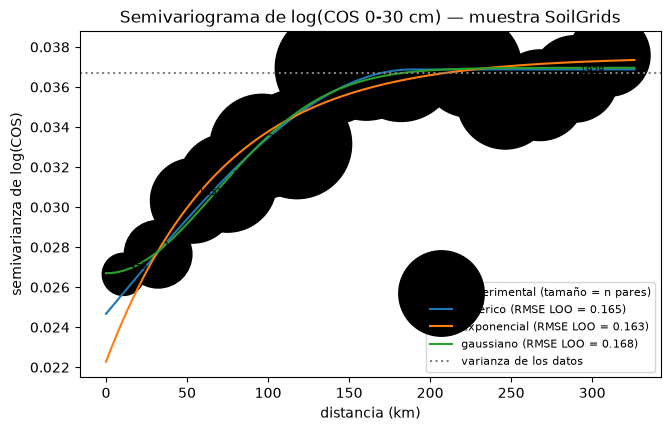

,psill,rango_m,pepita,pepita/meseta,R2_variograma,rango_en_limite,RMSE_LOO,MAE_LOO,ME_LOO,R2_LOO
esférico,0.012205,188690.217915,0.024671,0.66902,0.939289,False,0.165397,0.125025,-0.00008,0.254566
exponencial,0.015229,213244.27414,0.022275,0.59394,0.890036,False,0.163477,0.123281,0.0,0.271778
gaussiano,0.010264,166947.010316,0.026696,0.722302,0.936482,False,0.16817,0.127235,-0.000129,0.229366


Modelo elegido: exponencial | rango = 213 km | dependencia espacial MODERADA (25-75 %)
¿Rango en el límite del ajuste?  {'esférico': False, 'exponencial': False, 'gaussiano': False}


In [50]:
x, y, z = cal_m.geometry.x.values, cal_m.geometry.y.values, cal_m["log_cos"].values
print(f"n = {len(z)} puntos")
tabla_cos, loo_cos, _ = comparar_modelos(x, y, z, "Semivariograma de log(COS 0-30 cm) — muestra SoilGrids",
                                         "log(COS)", n_bins=15)
display(tabla_cos.round(4))
mejor_cos = tabla_cos["RMSE_LOO"].astype(float).idxmin()
p_cos = tabla_cos.loc[mejor_cos].to_dict()
print(f"Modelo elegido: {mejor_cos} | rango = {p_cos['rango_m'] / 1000:.0f} km | {interpretar(p_cos)}")
print("¿Rango en el límite del ajuste? ", {m: bool(tabla_cos.loc[m, "rango_en_limite"]) for m in tabla_cos.index})


### E.2 Validación cruzada LOO y validación independiente (COS)
* **LOO**: se quita cada uno de los 300 puntos y se estima con los otros 299.
* **Validación independiente**: se estima en los 200 puntos de validación (nunca usados) y se compara con el valor del raster en esos puntos.

Métricas: RMSE (error típico), MAE (error absoluto medio), ME (sesgo; ideal 0) y R² (1 = perfecto; 0 = igual que usar la media).

,RMSE,MAE,ME,R2
LOO (log),0.163,0.123,0.000,0.272
"LOO (g/kg), sin corrección: exp(pred)",3.638,2.467,-0.298,0.250
"LOO (g/kg), con corrección lognormal",3.623,2.512,-0.034,0.256
"validación independiente (g/kg), con corrección",4.300,2.930,-0.270,0.115
referencia: media de calibración (g/kg),4.658,2.942,-0.897,-0.039


MSSE LOO (log COS): 0.97  (ideal ≈ 1)


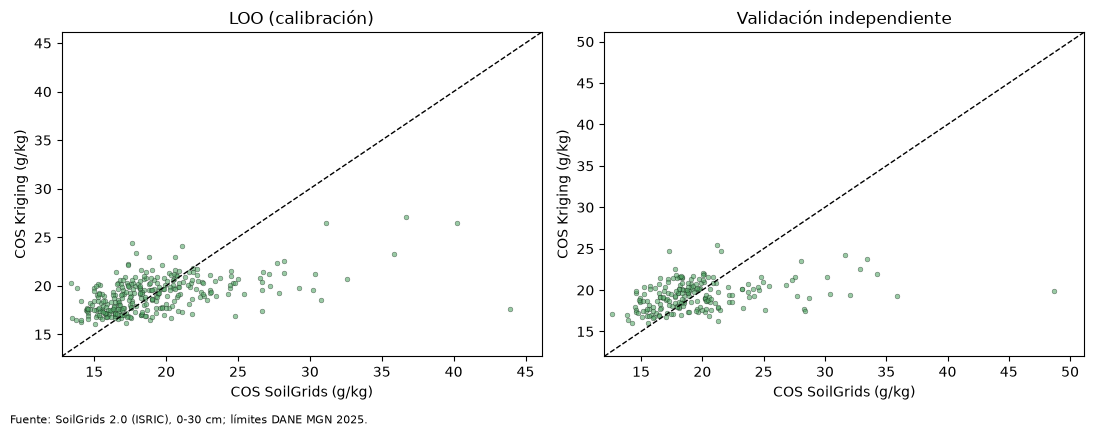

In [51]:
ok_cos = kriging_ok(x, y, z, MODELOS[mejor_cos], p_cos)
pv, vv = ok_cos.execute("points", val_m.geometry.x.values, val_m.geometry.y.values)
obs_cal, obs_val = cal_m["cos_gkg"].values, val_m["cos_gkg"].values
# Corrección lognormal: exp(pred) es la mediana; la media es exp(pred + var/2)
pred_loo_cos, var_loo_cos = loo_cos[mejor_cos]
cos_loo = np.exp(pred_loo_cos + var_loo_cos / 2)
cos_val = np.exp(np.asarray(pv) + np.asarray(vv) / 2)
met_cos = pd.DataFrame({
    "LOO (log)": metricas(z, loo_cos[mejor_cos][0]),
    "LOO (g/kg), sin corrección: exp(pred)": metricas(obs_cal, np.exp(pred_loo_cos)),
    "LOO (g/kg), con corrección lognormal": metricas(obs_cal, cos_loo),
    "validación independiente (g/kg), con corrección": metricas(obs_val, cos_val),
    "referencia: media de calibración (g/kg)": metricas(obs_val, np.full(len(obs_val), np.exp(z.mean()))),
}).T
display(met_cos.round(3))
print(f"MSSE LOO (log COS): {msse(z, pred_loo_cos, var_loo_cos):.2f}  (ideal ≈ 1)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a_, (o, p_, t) in zip(ax, [(obs_cal, cos_loo, "LOO (calibración)"),
                               (obs_val, cos_val, "Validación independiente")]):
    a_.scatter(o, p_, s=12, alpha=0.6, c="#55A868", edgecolor="k", lw=0.3)
    lim = [min(o.min(), p_.min()) * 0.95, max(o.max(), p_.max()) * 1.05]
    a_.plot(lim, lim, "k--", lw=1); a_.set_xlim(lim); a_.set_ylim(lim)
    a_.set_xlabel("COS SoilGrids (g/kg)"); a_.set_ylabel("COS Kriging (g/kg)"); a_.set_title(t)
plt.tight_layout()
fuente()
plt.show()

### E.3 Mapas de predicción y de varianza (COS)
Grilla común de 2 km (EPSG:9377) sobre los 7 municipios.

Celdas del kriging: 33,912 | coinciden con un id_celda: 33,912 | celdas de la grilla común: 34,763


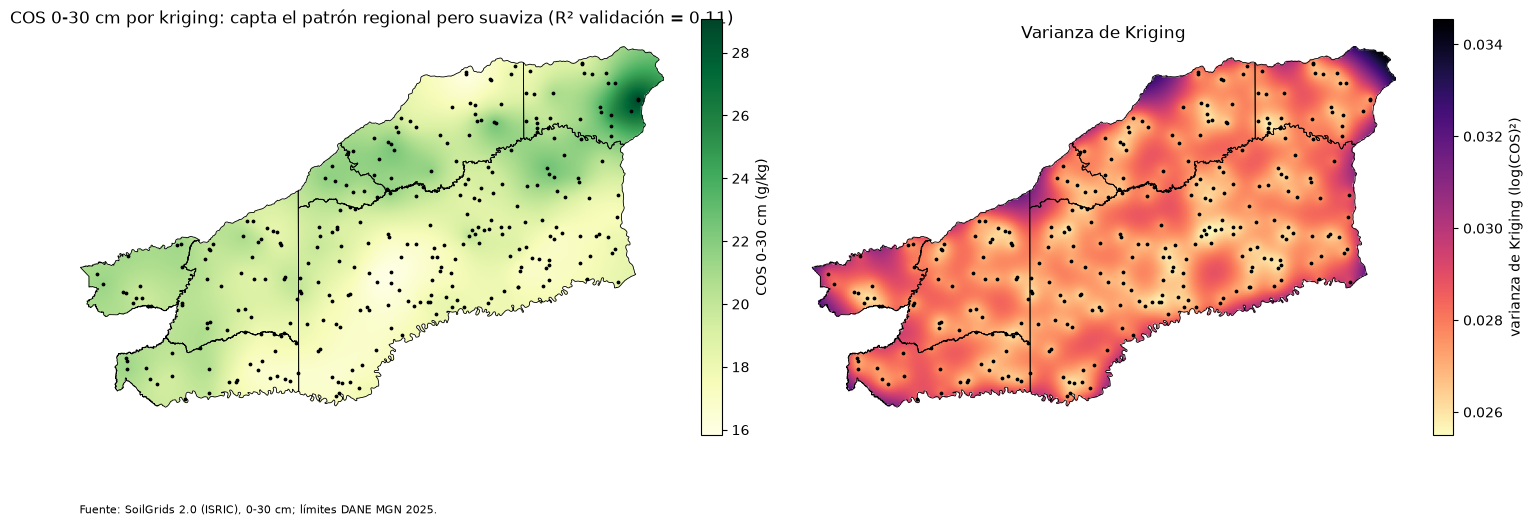

In [52]:
gx, gy, dentro = grilla(mun_m, CELDA)
ext = [gx[0] - CELDA / 2, gx[-1] + CELDA / 2, gy[0] - CELDA / 2, gy[-1] + CELDA / 2]

# Cada celda del kriging debe ser un id_celda de la grilla común (esquina inferior izquierda en km)
traer("datos/comunes/grilla_2km.gpkg")
grilla_comun = gpd.read_file(COMUNES / "grilla_2km.gpkg")
XX, YY = np.meshgrid(gx, gy)
ids_krig = np.array([f"x{int(cx - CELDA / 2) // 1000}_y{int(cy - CELDA / 2) // 1000}"
                     for cx, cy in zip(XX[dentro], YY[dentro])])
faltan = set(ids_krig) - set(grilla_comun["id_celda"])
print(f"Celdas del kriging: {len(ids_krig):,} | coinciden con un id_celda: {len(ids_krig) - len(faltan):,} "
      f"| celdas de la grilla común: {len(grilla_comun):,}")
assert not faltan, f"{len(faltan)} celdas del kriging no están en grilla_2km.gpkg"


def mapas(pred, var, puntos, titulo, cmap, etiqueta, etiqueta_var, vmin=None, vmax=None):
    fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
    im = ax[0].imshow(pred, origin="lower", extent=ext, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.colorbar(im, ax=ax[0], shrink=0.8, label=etiqueta)
    ax[0].set_title(titulo)
    im = ax[1].imshow(var, origin="lower", extent=ext, cmap="magma_r")
    plt.colorbar(im, ax=ax[1], shrink=0.8, label=etiqueta_var)
    ax[1].set_title("Varianza de Kriging")
    for a_ in ax:
        mun_m.boundary.plot(ax=a_, color="k", lw=0.6)
        puntos.plot(ax=a_, color="k", markersize=3)
        a_.set_xlim(ext[0], ext[1]); a_.set_ylim(ext[2], ext[3]); a_.set_axis_off()
    fuente()
    plt.tight_layout()
    plt.show()


zg, sg = ok_cos.execute("masked", gx, gy, mask=~dentro)
zg, sg = np.ma.filled(zg, np.nan), np.ma.filled(sg, np.nan)
cos_mapa = np.exp(zg + sg / 2)        # corrección lognormal
mapas(cos_mapa, sg, cal_m, f"COS 0-30 cm por kriging: capta el patrón regional pero suaviza "
      f"(R² validación = {met_cos.loc['validación independiente (g/kg), con corrección', 'R2']:.2f})", "YlGn",
      "COS 0-30 cm (g/kg)", "varianza de Kriging (log(COS)²)")

### E.4 Comparación del mapa de Kriging con el raster SoilGrids
El raster de ~278 m se lleva a la misma grilla de 2 km (EPSG:9377) promediando los píxeles que caen en cada celda, y se compara celda a celda con la predicción del Kriging.

Celdas comparadas: 33,912


,RMSE,MAE,ME,R2
"Kriging vs. raster (todas las celdas de 2 km, g/kg)",3.046,2.027,-0.403,0.275


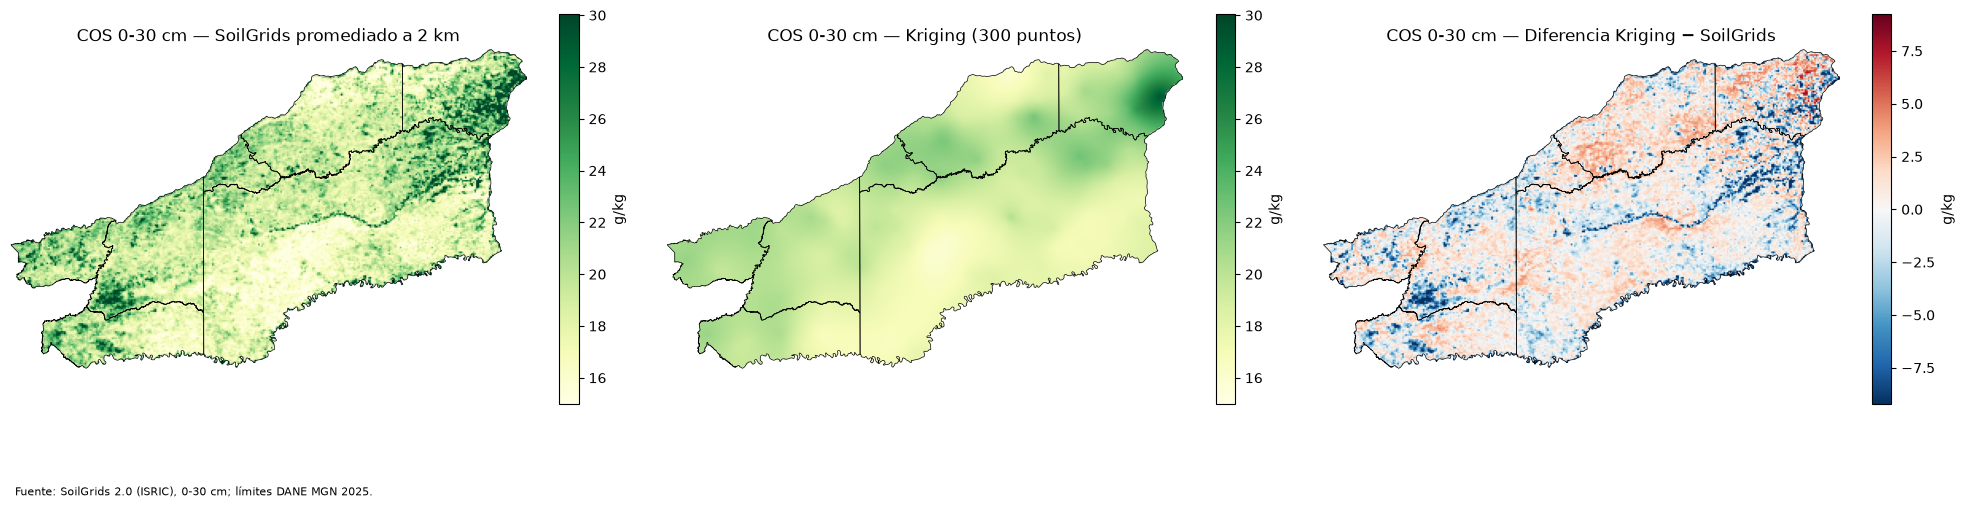

In [53]:
tr_grid = from_origin(ext[0], ext[3], CELDA, CELDA)


def raster_a_grilla(a):
    dst = np.full((len(gy), len(gx)), np.nan, dtype="float64")
    reproject(a, dst, src_transform=transform, src_crs=crs_r, dst_transform=tr_grid, dst_crs=CRS_M,
              resampling=Resampling.average, src_nodata=np.nan, dst_nodata=np.nan)
    return np.flipud(dst)        # filas de sur a norte, igual que la salida de pykrige


sg_cos = raster_a_grilla(r030["cos_gkg"])
sg_cos[~dentro] = np.nan
ok_ = np.isfinite(sg_cos) & np.isfinite(cos_mapa)
m_mapa_cos = metricas(sg_cos[ok_], cos_mapa[ok_])
print(f"Celdas comparadas: {ok_.sum():,}")
display(pd.DataFrame({"Kriging vs. raster (todas las celdas de 2 km, g/kg)": m_mapa_cos}).T.round(3))

dif = cos_mapa - sg_cos
lim = np.nanpercentile(np.abs(dif), 98)
vmin, vmax = np.nanpercentile(sg_cos, [2, 98])
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
for a_, (arr, t, cm, v0, v1) in zip(ax, [(sg_cos, "SoilGrids promediado a 2 km", "YlGn", vmin, vmax),
                                         (cos_mapa, "Kriging (300 puntos)", "YlGn", vmin, vmax),
                                         (dif, "Diferencia Kriging − SoilGrids", "RdBu_r", -lim, lim)]):
    im = a_.imshow(arr, origin="lower", extent=ext, cmap=cm, vmin=v0, vmax=v1)
    plt.colorbar(im, ax=a_, shrink=0.75, label="g/kg")
    mun_m.boundary.plot(ax=a_, color="k", lw=0.5)
    a_.set_title(f"COS 0-30 cm — {t}"); a_.set_axis_off()
plt.tight_layout()
fuente()
plt.show()

### E.5 pH 0-30 cm
Mismo procedimiento, sin transformación.

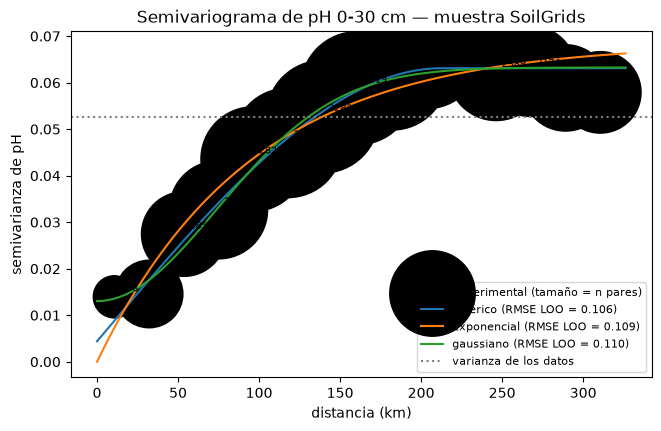

,psill,rango_m,pepita,pepita/meseta,R2_variograma,rango_en_limite,RMSE_LOO,MAE_LOO,ME_LOO,R2_LOO
esférico,0.058709,212768.79411,0.004391,0.069593,0.973289,False,0.106091,0.080567,0.000452,0.786281
exponencial,0.068474,284358.463694,0.0,0.0,0.936936,False,0.109097,0.082156,0.000753,0.774
gaussiano,0.05021,183055.097541,0.013041,0.206178,0.974331,False,0.110106,0.083776,-0.000138,0.769799


Modelo elegido: esférico | rango = 213 km | dependencia espacial FUERTE (pepita/meseta < 25 %)
¿Rango en el límite del ajuste?  {'esférico': False, 'exponencial': False, 'gaussiano': False}
MSSE LOO (pH): 1.11  (ideal ≈ 1)


,RMSE,MAE,ME,R2
LOO,0.106,0.081,0.000,0.786
validación independiente,0.114,0.082,-0.008,0.736
referencia: media de calibración,0.229,0.201,-0.054,-0.059
Kriging vs. raster (celdas de 2 km),0.094,0.066,-0.003,0.802


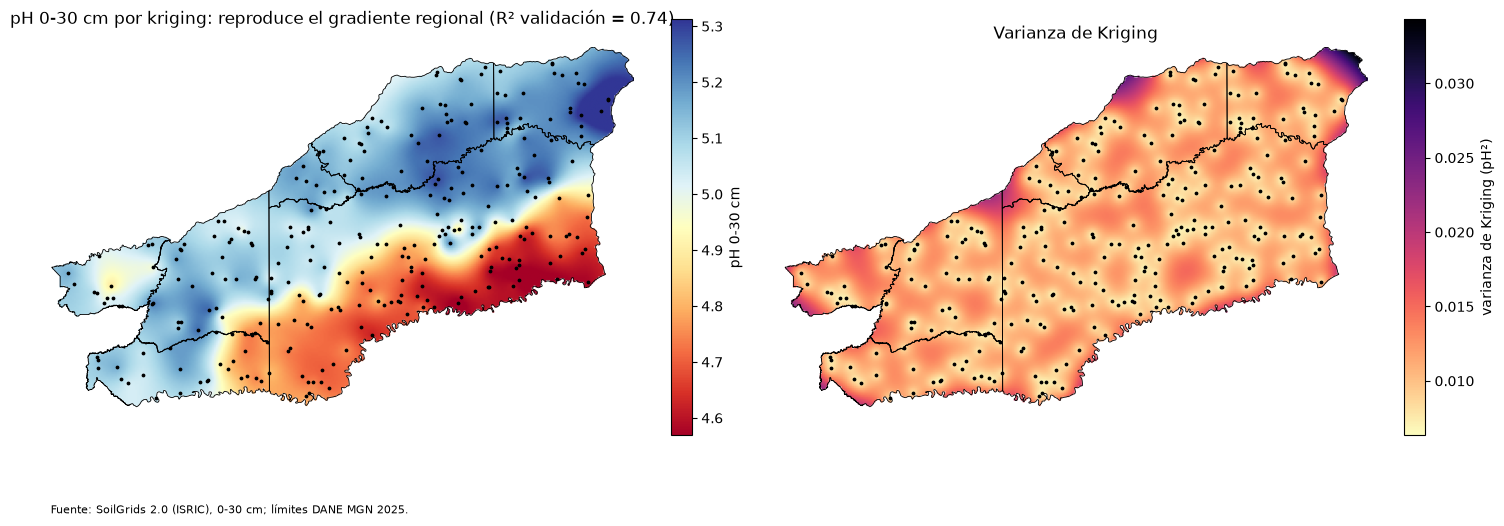

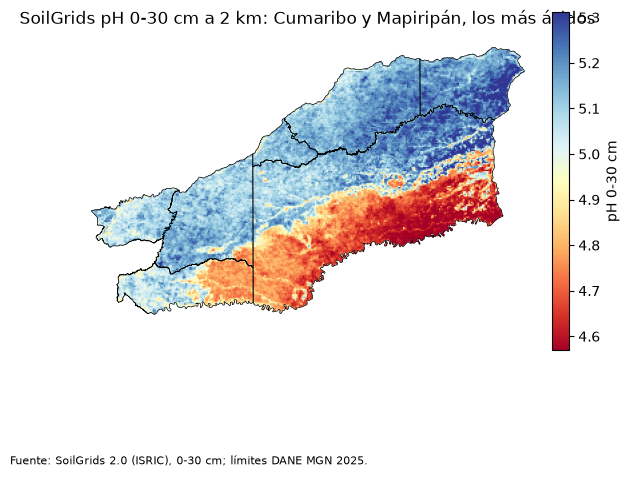

In [54]:
xp, yp, zp = cal_m.geometry.x.values, cal_m.geometry.y.values, cal_m["ph"].values
tabla_ph, loo_ph, _ = comparar_modelos(xp, yp, zp, "Semivariograma de pH 0-30 cm — muestra SoilGrids", "pH", n_bins=15)
display(tabla_ph.round(4))
mejor_ph = tabla_ph["RMSE_LOO"].astype(float).idxmin()
p_ph = tabla_ph.loc[mejor_ph].to_dict()
print(f"Modelo elegido: {mejor_ph} | rango = {p_ph['rango_m'] / 1000:.0f} km | {interpretar(p_ph)}")
print("¿Rango en el límite del ajuste? ", {m: bool(tabla_ph.loc[m, "rango_en_limite"]) for m in tabla_ph.index})
print(f"MSSE LOO (pH): {msse(zp, *loo_ph[mejor_ph]):.2f}  (ideal ≈ 1)")

ok_ph = kriging_ok(xp, yp, zp, MODELOS[mejor_ph], p_ph)
pvp, _ = ok_ph.execute("points", val_m.geometry.x.values, val_m.geometry.y.values)
zgp, sgp = ok_ph.execute("masked", gx, gy, mask=~dentro)
zgp, sgp = np.ma.filled(zgp, np.nan), np.ma.filled(sgp, np.nan)
sg_ph = raster_a_grilla(r030["ph"])
sg_ph[~dentro] = np.nan
okp = np.isfinite(sg_ph) & np.isfinite(zgp)
met_ph = pd.DataFrame({
    "LOO": metricas(zp, loo_ph[mejor_ph][0]),
    "validación independiente": metricas(val_m["ph"].values, np.asarray(pvp)),
    "referencia: media de calibración": metricas(val_m["ph"].values, np.full(len(val_m), zp.mean())),
    "Kriging vs. raster (celdas de 2 km)": metricas(sg_ph[okp], zgp[okp]),
}).T
display(met_ph.round(3))
vmin, vmax = np.nanpercentile(sg_ph, [2, 98])
mapas(zgp, sgp, cal_m, f"pH 0-30 cm por kriging: reproduce el gradiente regional "
      f"(R² validación = {met_ph.loc['validación independiente', 'R2']:.2f})", "RdYlBu", "pH 0-30 cm",
      "varianza de Kriging (pH²)", vmin, vmax)
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(sg_ph, origin="lower", extent=ext, cmap="RdYlBu", vmin=vmin, vmax=vmax)
plt.colorbar(im, ax=ax, shrink=0.8, label="pH 0-30 cm")
mun_m.boundary.plot(ax=ax, color="k", lw=0.5)
ax.set_title("SoilGrids pH 0-30 cm a 2 km: Cumaribo y Mapiripán, los más ácidos"); ax.set_axis_off()
fuente()
plt.show()

### E.6 ¿Cuántos puntos hacen falta? (sensibilidad al tamaño de muestra)
Se repite el Kriging del COS con submuestras de 30, 60, 100, 200 y 300 puntos (usando el mismo semivariograma) y se mide el error en los 200 puntos de validación. Esto ayuda a interpretar los resultados de WoSIS (9-27 sitios).

,RMSE,MAE,ME,R2
n_puntos,,,,
30,4.412,2.909,-0.280,0.068
60,4.520,2.944,-0.476,0.022
100,4.349,2.856,-0.316,0.095
200,4.300,2.913,-0.294,0.115
300,4.300,2.930,-0.270,0.115


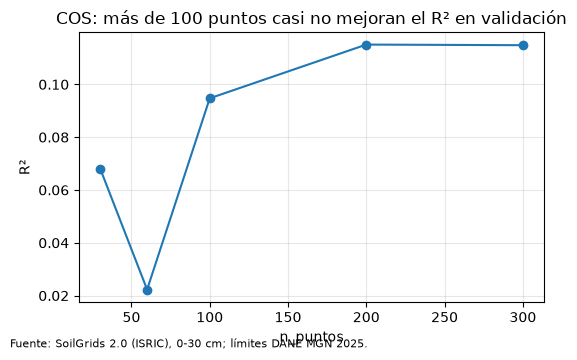

In [55]:
filas = []
orden = np.random.default_rng(SEMILLA).permutation(len(z))
for n in [30, 60, 100, 200, 300]:
    s = orden[:n]
    pz, vz = kriging_ok(x[s], y[s], z[s], MODELOS[mejor_cos], p_cos).execute(
        "points", val_m.geometry.x.values, val_m.geometry.y.values)
    filas.append({"n_puntos": n, **metricas(obs_val, np.exp(np.asarray(pz) + np.asarray(vz) / 2))})
sens = pd.DataFrame(filas).set_index("n_puntos")
display(sens.round(3))
sens["R2"].plot(marker="o", figsize=(6, 3.5), title="COS: más de 100 puntos casi no mejoran el R² en validación")
plt.ylabel("R²"); plt.grid(alpha=0.3)
fuente()
plt.show()

### E.7 Guardado de resultados

In [56]:
def guardar_tif(arr, nombre):
    with rasterio.open(DATOS / "soilgrids" / nombre, "w", driver="GTiff", height=arr.shape[0], width=arr.shape[1],
                       count=1, dtype="float32", crs=CRS_M, transform=tr_grid, nodata=np.nan) as dst:
        dst.write(np.flipud(arr).astype("float32"), 1)


guardar_tif(cos_mapa, "kriging_cos_0_30_gkg.tif"); guardar_tif(sg, "kriging_cos_0_30_varianza_log.tif")
guardar_tif(zgp, "kriging_ph_0_30.tif"); guardar_tif(sgp, "kriging_ph_0_30_varianza.tif")
resumen = pd.DataFrame([
    {"fuente": "SoilGrids (muestra)", "propiedad": "COS 0-30 cm (g/kg; kriging en log)", "n_puntos": len(z),
     "modelo": mejor_cos, "rango_km": p_cos["rango_m"] / 1000, "rango_en_limite": p_cos["rango_en_limite"],
     "pepita/meseta": p_cos["pepita/meseta"], "MSSE_LOO": msse(z, pred_loo_cos, var_loo_cos),
     **{f"{k}_LOO": v for k, v in metricas(obs_cal, cos_loo).items()},
     **{f"{k}_valid": v for k, v in metricas(obs_val, cos_val).items()}},
    {"fuente": "SoilGrids (muestra)", "propiedad": "pH 0-30 cm", "n_puntos": len(zp),
     "modelo": mejor_ph, "rango_km": p_ph["rango_m"] / 1000, "rango_en_limite": p_ph["rango_en_limite"],
     "pepita/meseta": p_ph["pepita/meseta"], "MSSE_LOO": msse(zp, *loo_ph[mejor_ph]),
     **{f"{k}_LOO": v for k, v in metricas(zp, loo_ph[mejor_ph][0]).items()},
     **{f"{k}_valid": v for k, v in metricas(val_m["ph"].values, np.asarray(pvp)).items()}},
])
resumen.to_csv(DATOS / "soilgrids" / "resumen_validacion_soilgrids.csv", index=False)
display(resumen.round(3).T)

# Predicción del kriging por id_celda (insumo del cuaderno 42)
kriging_celda = pd.DataFrame({"id_celda": ids_krig,
                              "ph_kriging": zgp[dentro], "ph_kriging_var": sgp[dentro],
                              "cos_kriging_gkg": cos_mapa[dentro], "cos_kriging_var_log": sg[dentro]})
kriging_celda.to_csv(DATOS / "soilgrids" / "kriging_celda.csv", index=False)
print("kriging_celda.csv:", kriging_celda.shape)


,0,1
fuente,SoilGrids (muestra),SoilGrids (muestra)
propiedad,COS 0-30 cm (g/kg; kriging en log),pH 0-30 cm
n_puntos,300,300
modelo,exponencial,esférico
rango_km,213.244,212.769
rango_en_limite,False,False
pepita/meseta,0.594,0.07
MSSE_LOO,0.966,1.114
RMSE_LOO,3.623,0.106
MAE_LOO,2.512,0.081


kriging_celda.csv: (33912, 5)


### E.8 Benchmark: IDW (inverso de la distancia, potencia 2)
Regla del equipo: un modelo solo vale si le gana a una referencia simple en datos que no vio. Se compara el Kriging ordinario con IDW en la misma validación cruzada LOO y en los 200 puntos de validación.

In [57]:
def idw(xc, yc, zc, xp, yp, potencia=2):
    d = np.hypot(xp[:, None] - xc[None, :], yp[:, None] - yc[None, :])
    w = 1 / np.maximum(d, 1e-9) ** potencia
    return (w * zc).sum(1) / w.sum(1)


def idw_loo(x, y, z, potencia=2):
    pred = np.empty_like(z, dtype=float)
    for i in range(len(z)):
        m = np.arange(len(z)) != i
        pred[i] = idw(x[m], y[m], z[m], x[i:i + 1], y[i:i + 1], potencia)[0]
    return pred


xc, yc = cal_m.geometry.x.values, cal_m.geometry.y.values
xv, yv = val_m.geometry.x.values, val_m.geometry.y.values
filas = {}
for et, zc, obs_v, krig_loo, krig_val, back in [
        ("pH", cal_m["ph"].values, val_m["ph"].values, loo_ph[mejor_ph][0], np.asarray(pvp), lambda v: v),
        ("COS (g/kg)", cal_m["log_cos"].values, val_m["cos_gkg"].values, cos_loo, cos_val, np.exp)]:
    obs_c = back(zc)
    filas[(et, "IDW p=2", "LOO")] = metricas(obs_c, back(idw_loo(xc, yc, zc)))
    filas[(et, "Kriging ordinario", "LOO")] = metricas(obs_c, krig_loo)
    filas[(et, "IDW p=2", "validación")] = metricas(obs_v, back(idw(xc, yc, zc, xv, yv)))
    filas[(et, "Kriging ordinario", "validación")] = metricas(obs_v, krig_val)
bench = pd.DataFrame(filas).T
bench.index.names = ["propiedad", "método", "conjunto"]
bench.to_csv(DATOS / "soilgrids" / "benchmark_idw_vs_kriging.csv")
display(bench.round(3))

RMSE    MAE     ME     R2
propiedad  método            conjunto                              
pH         IDW p=2           LOO         0.118  0.095  0.000  0.735
           Kriging ordinario LOO         0.106  0.081  0.000  0.786
           IDW p=2           validación  0.123  0.096 -0.022  0.696
           Kriging ordinario validación  0.114  0.082 -0.008  0.736
COS (g/kg) IDW p=2           LOO         3.567  2.477 -0.247  0.279
           Kriging ordinario LOO         3.623  2.512 -0.034  0.256
           IDW p=2           validación  4.379  2.912 -0.590  0.082
           Kriging ordinario validación  4.300  2.930 -0.270  0.115

## F. Conclusiones

1. **SoilGrids es un modelo, no una medición.** Aquí sirve como "verdad conocida" para evaluar el kriging y como covariable para análisis posteriores. En la Altillanura se entrenó con muy pocos perfiles locales, así que sus valores absolutos también son inciertos; la comparación con perfiles medidos (WoSIS) y con el mapa de pH del IGAC está en el cuaderno 41.
2. **Muestra:** 300 puntos de calibración y 200 de validación, al azar dentro de los 7 municipios con los límites comunes (135.649 km², EPSG:9377), cerca de 1 punto cada 450 km².
3. **pH 0-30 cm:** semivariograma esférico con estructura espacial fuerte (pepita/meseta = 0,07; rango ≈ 213 km, que no queda en el límite del ajuste). Validación cruzada LOO: **RMSE = 0,106, MAE = 0,081, ME = 0,000, R² = 0,79, MSSE = 1,11**; validación independiente: RMSE = 0,114, R² = 0,74; frente al raster promediado a 2 km: R² = 0,80. **Le gana al benchmark IDW** (LOO: RMSE = 0,118, R² = 0,73; validación: R² = 0,70).
4. **COS 0-30 cm (kriging en log):** dependencia espacial moderada (exponencial, pepita/meseta = 0,59, rango ≈ 213 km, no está en el límite). Con la corrección lognormal `exp(pred + var/2)` el sesgo LOO baja de −0,30 a **−0,03 g/kg**. LOO: **RMSE = 3,62 g/kg, MAE = 2,51, R² = 0,26, MSSE = 0,97**; validación independiente: RMSE = 4,30, ME = −0,27, R² = 0,11; frente al raster a 2 km: R² = 0,28. **No mejora claramente a IDW** (LOO: R² = 0,28; validación: R² = 0,08): el carbono de SoilGrids cambia a escalas cortas (vegas, bosques de galería) que 300 puntos separados ~20 km no captan.
5. **Calibración de la varianza:** el MSSE es ≈ 1 en las dos propiedades (0,97 y 1,11), así que los mapas de varianza del kriging son una medida de incertidumbre razonable.
6. **Tamaño de muestra (COS):** el R² en validación va de 0,07 con 30 puntos a 0,10-0,12 desde 100 puntos; entre 200 y 300 no cambia.
7. **Por qué cambian las cifras frente a la versión anterior (03):** con los límites comunes (MGN 2025 en vez de geoBoundaries) y EPSG:9377 cambia la máscara de los municipios, y con ella la muestra aleatoria (misma semilla, distinta área). Por eso el rango del COS pasa de ≈ 110 a ≈ 213 km y la pepita/meseta de 0,45 a 0,59.
8. **Unión con la grilla común:** las 33.912 celdas del kriging coinciden con un `id_celda` de `grilla_2km.gpkg`. La predicción por celda queda en `kriging_celda.csv` para el cuaderno 42.
9. **Qué dice SoilGrids de la zona:** pH 0-30 cm medio = 5,02 (p10-p90: 4,7-5,25), con Cumaribo (4,91) y Mapiripán (4,94) como los más ácidos; COS medio = 19,6 g/kg (p10-p90: 15,5-24,5), más alto en Puerto Carreño (22,3) y Puerto López (21,3), y concentrado en superficie (31,9 g/kg en 0-5 cm frente a 14,4 en 15-30 cm). pH y COS tienen una relación positiva débil (Pearson = 0,35; Spearman = 0,45).
10. **Conclusión práctica y pendientes:** el kriging ordinario funciona bien para el pH (variable suave y regional) y de forma limitada para el carbono. El siguiente paso es un kriging de regresión o con deriva externa con elevación y lluvia media por celda (cuaderno 12) como covariables, validado con perfiles medidos (cuaderno 41).
